# Project 6 — Part 2b: Time-Series Analysis of Rossmann Sales

**Purpose.** Understand the *temporal behaviour* of Rossmann sales — trend, seasonality, weekday and holiday effects, stationarity, autocorrelation — and turn it into concrete design decisions for the LSTM notebook (`04_LSTM_Modeling.ipynb`). This covers steps 1–4 of PDF item 2.6 (isolate the series, check stationarity, decide on differencing, check ACF/PACF) and goes further on trend, seasonality and holidays.

**Not repeated here:** the cleaning, outlier and question-by-question EDA of `01_eda.ipynb` (promotions, competition, assortment, …) and the supervised models of `02_ML_Modeling.ipynb`.

| Section | Content |
|---|---|
| 1 | Setup, loading, date parsing and chronological sorting |
| 2 | Time-series indexing — defining the series to analyse |
| 3 | Daily, weekly and monthly trends |
| 4 | Seasonality: weekly, two-weekly (promotions) and yearly; STL decomposition |
| 5 | Weekday and weekend patterns |
| 6 | Holiday effects (Easter, public holidays, Christmas) |
| 7 | Store-type temporal patterns |
| 8 | Stationarity (ADF and KPSS) and the differencing decision |
| 9 | ACF and PACF |
| 10 | Naive benchmarks (what any forecasting model must beat) |
| 11 | Insights and decisions handed to the LSTM notebook |

**Data:** only the raw files `train.csv` and `store.csv` in `data/raw/` (never modified).
**Important rule used throughout:** the last **42 days are a hold-out** that is not used for any statistical decision (stationarity, differencing, window size, seasonal periods). It is only touched in section 10 to score the naive benchmarks.

## 1. Setup, loading, date parsing and chronological sorting

In [2]:
import logging, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S", force=True)
log = logging.getLogger("rossmann.ts")
logging.getLogger("matplotlib").setLevel(logging.WARNING)

SEED = 42
BLUE, ORANGE, AQUA, YELLOW, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "raw"
for f in ("train.csv", "store.csv"):
    if not (DATA_DIR / f).exists():
        raise FileNotFoundError(f"Missing {f}. Expected at: {DATA_DIR / f}")
log.info("Raw data folder: %s | pandas %s | statsmodels %s", DATA_DIR, pd.__version__, statsmodels.__version__)

ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
t0 = time.time()
train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["Date"],
                    dtype={"Store": "int16", "DayOfWeek": "int8", "Sales": "int32", "Customers": "int16",
                           "Open": "int8", "Promo": "int8", "StateHoliday": "str", "SchoolHoliday": "int8"})
store = pd.read_csv(DATA_DIR / "store.csv", usecols=["Store", "StoreType", "Assortment"])
log.info("Loaded train %s and store %s in %.1fs", train.shape, store.shape, time.time() - t0)

# Date parsing check and chronological order. The raw file is NOT in chronological order, so we sort explicitly.
print("Date dtype:", train.Date.dtype, "| raw file in ascending date order:", train.Date.is_monotonic_increasing,
      "| in descending order:", train.Date.is_monotonic_decreasing)
train = train.sort_values(["Date", "Store"]).reset_index(drop=True)
print("After sorting -> ascending:", train.Date.is_monotonic_increasing, "| first/last date:", train.Date.min().date(), train.Date.max().date())
assert (train.Date.dt.dayofweek + 1 == train.DayOfWeek).all(), "DayOfWeek does not match Date"
assert not train.duplicated(["Store", "Date"]).any(), "duplicate (Store, Date)"

06:32:13 | INFO    | Loaded train (1017209, 9) and store (1115, 3) in 0.5s


Date dtype: datetime64[us] | raw file in ascending date order: False | in descending order: True
After sorting -> ascending: True | first/last date: 2013-01-01 2015-07-31


**Why sorting matters:** every time-series tool (rolling means, lags, differences, ACF) assumes the rows are in time order. The raw file lists the newest day first, so without sorting a `shift(1)` would silently look at the *future*.

## 2. Time-series indexing — which series do we analyse?

The data has about 1,115 stores × 942 days. A time-series model needs **one number per day**. We define the main series as

> **`y(t)` = average sales per *trading* store on day `t`** (`Open == 1` and `Sales > 0`).

**Why the average and not the total?** The *total* depends on how many stores are open: on Sundays only a few dozen stores trade, so the total collapses (a Sunday effect that says nothing about demand per store). The average per trading store removes most of that. Its weakness: if the *mix* of stores changes from day to day (Sundays, holidays, missing store rows), the average changes too. We make this visible below and test it with a fixed panel of stores.

In [ ]:
trading = (train.Open == 1) & (train.Sales > 0)
op = train[trading]                                              # trading rows only (a filtered copy of ~0.8 M rows)

daily = op.groupby("Date").agg(mean_sales=("Sales", "mean"), total_sales=("Sales", "sum"), n_trading=("Store", "size"))
daily["n_rows"] = train.groupby("Date").size()                   # stores that have a row at all that day
daily = daily.asfreq("D")                                        # regular daily DatetimeIndex; gaps would become NaN
n_missing_days = int(daily.mean_sales.isna().sum())
assert n_missing_days == 0, "the calendar has missing days"

y = daily.mean_sales.astype("float64")                           # <- the series analysed in this notebook
last_day = y.index.max(); cut = last_day - pd.Timedelta(days=41)  # last 42 days = hold-out
y_tr, y_ho = y[y.index < cut], y[y.index >= cut]
tot_tr = daily.total_sales[daily.index < cut]
print(f"{len(y)} days | {y.index.min().date()} -> {last_day.date()} | index frequency: {y.index.freq} | missing days: {n_missing_days}")
print(f"training part: {len(y_tr)} days ({y_tr.index[0].date()} -> {y_tr.index[-1].date()}) | hold-out: {len(y_ho)} days ({y_ho.index[0].date()} -> {y_ho.index[-1].date()})")
display(y_tr.describe().round(0).to_frame("y (training part), EUR per trading store"))

942 days | 2013-01-01 -> 2015-07-31 | index frequency: <Day> | missing days: 0
training part: 900 days (2013-01-01 -> 2015-06-19) | hold-out: 42 days (2015-06-20 -> 2015-07-31)


,"y (training part), EUR per trading store"
count,900.0
mean,7257.0
std,1771.0
min,4067.0
25%,5780.0
50%,7056.0
75%,8030.0
max,14263.0


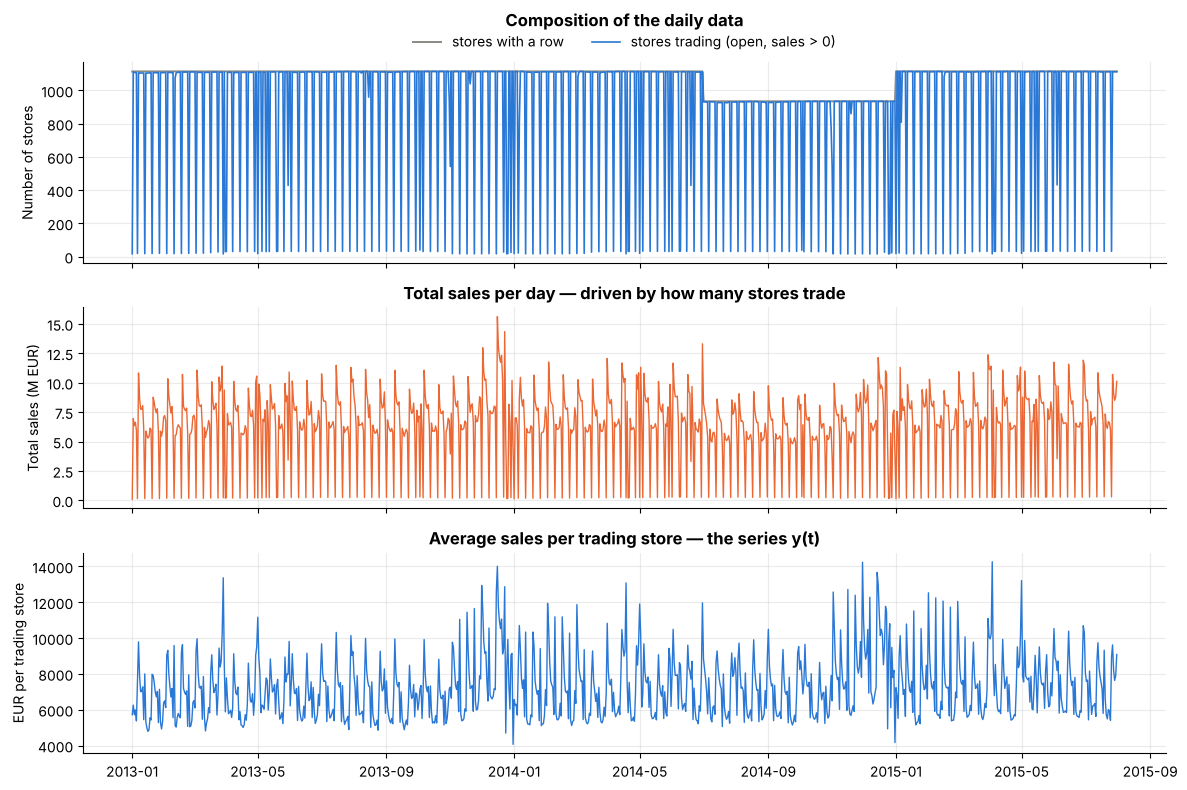

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(daily.index, daily.n_rows, color=GREY, lw=1.4, label="stores with a row")
axes[0].plot(daily.index, daily.n_trading, color=BLUE, lw=1.2, label="stores trading (open, sales > 0)")
axes[0].set_ylabel("Number of stores"); axes[0].legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5, 1.0)); axes[0].set_title("Composition of the daily data", pad=26)
axes[1].plot(daily.index, daily.total_sales / 1e6, color=ORANGE, lw=1.0); axes[1].set_ylabel("Total sales (M EUR)"); axes[1].set_title("Total sales per day — driven by how many stores trade")
axes[2].plot(daily.index, y, color=BLUE, lw=1.0); axes[2].set_ylabel("EUR per trading store"); axes[2].set_title("Average sales per trading store — the series y(t)")
plt.tight_layout(); plt.show()

In [ ]:
# Robustness: a FIXED panel of stores (those with a row on every one of the 942 days) removes any store-mix effect.
rows_per_store = train.groupby("Store").size()
panel = rows_per_store[rows_per_store == len(daily)].index
y_panel = op[op.Store.isin(panel)].groupby("Date").Sales.mean().reindex(daily.index)
both = pd.concat([y, y_panel], axis=1, keys=["all", "panel"]).dropna()
corr_lvl = both.corr().iloc[0, 1]; corr_d1 = both.diff().dropna().corr().iloc[0, 1]
mean_gap = ((both["all"] - both["panel"]).abs() / both["panel"]).mean()
display(Markdown(
f"**Store-mix check.** {len(panel)} of {store.shape[0]} stores have a row on all {len(daily)} days; the fixed-panel series has correlation **{corr_lvl:.3f}** "
f"with y(t) in levels and **{corr_d1:.3f}** in day-to-day changes; on average the two differ by {mean_gap:.1%}. "
f"{'The store mix is therefore not the main driver of y(t).' if corr_d1 > .9 else 'The store mix does influence the day-to-day changes of y(t) — keep this in mind when reading the results.'}"))

**Store-mix check.** 934 of 1115 stores have a row on all 942 days; the fixed-panel series has correlation **0.999** with y(t) in levels and **0.999** in day-to-day changes; on average the two differ by 1.0%. The store mix is therefore not the main driver of y(t).

## 3. Daily, weekly and monthly trends
**What to look for:** a slow upward or downward drift (trend), and whether it is the same in every year.

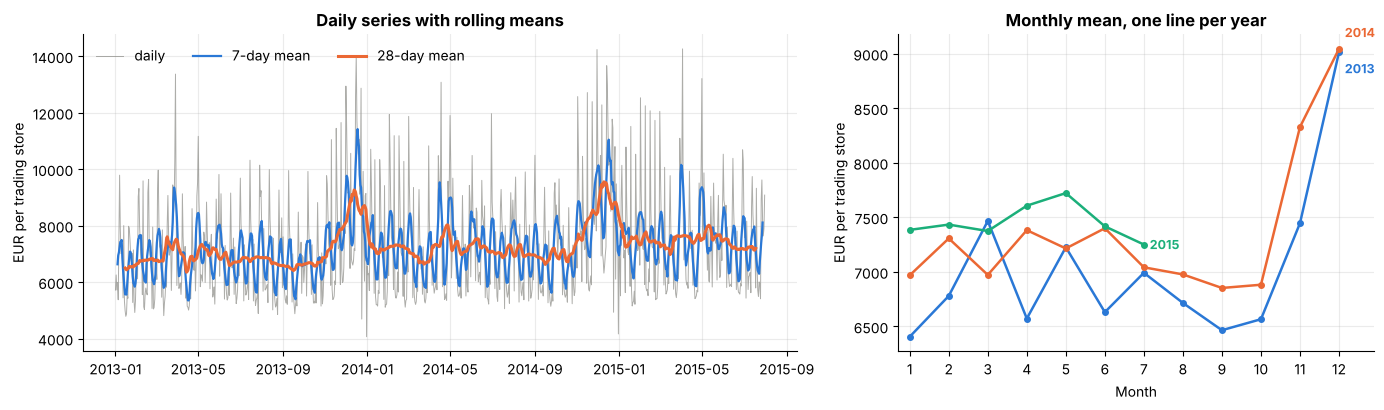

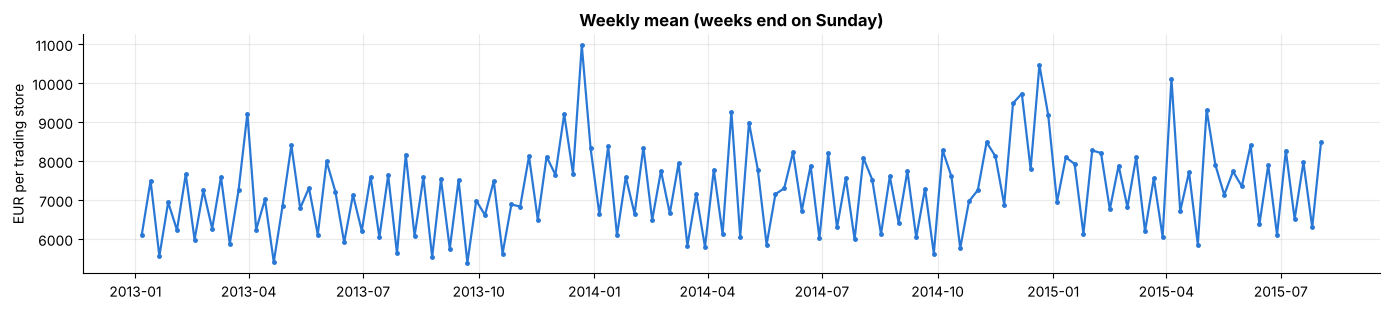

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.plot(y.index, y, color=GREY, lw=.7, alpha=.7, label="daily")
ax.plot(y.index, y.rolling(7, center=True).mean(), color=BLUE, lw=1.6, label="7-day mean")
ax.plot(y.index, y.rolling(28, center=True).mean(), color=ORANGE, lw=2.2, label="28-day mean")
ax.set_ylabel("EUR per trading store"); ax.set_title("Daily series with rolling means"); ax.legend(frameon=False, ncol=3, loc="upper left")
ym = y.groupby([y.index.year, y.index.month]).mean().unstack(0)             # rows = month, columns = year
for yr, col in zip(ym.columns, [BLUE, ORANGE, AQUA]):
    s = ym[yr].dropna(); axes[1].plot(s.index, s.values, marker="o", ms=4, color=col, lw=1.8)
    axes[1].text(s.index[-1] + .15, s.values[-1] + {2013: -150, 2014: 150, 2015: 0}[yr], str(yr), color=col, va="center", fontsize=9, fontweight="bold")
axes[1].set_xticks(range(1, 13)); axes[1].set_xlim(.7, 12.9); axes[1].set_xlabel("Month"); axes[1].set_ylabel("EUR per trading store")
axes[1].set_title("Monthly mean, one line per year")
plt.tight_layout(); plt.show()

wk = y.resample("W-SUN").mean()
fig, ax = plt.subplots(figsize=(14, 3.2)); ax.plot(wk.index, wk.values, color=BLUE, lw=1.6, marker="o", ms=2.5)
ax.set_ylabel("EUR per trading store"); ax.set_title("Weekly mean (weeks end on Sunday)"); plt.tight_layout(); plt.show()

In [ ]:
# Year-on-year change using the same months (Jan-Jul exist in all three years)
jj = ym.loc[1:7]
g14, g15 = jj[2014].mean() / jj[2013].mean() - 1, jj[2015].mean() / jj[2014].mean() - 1
ymp = y_panel.groupby([y_panel.index.year, y_panel.index.month]).mean().unstack(0).loc[1:7]
p14, p15 = ymp[2014].mean() / ymp[2013].mean() - 1, ymp[2015].mean() / ymp[2014].mean() - 1
slope = np.polyfit(np.arange(len(y_tr)), y_tr.values, 1)[0] * 365
display(Markdown(
f"**Trend findings.** Comparing the same months (Jan–Jul): **2014 vs 2013 {g14:+.1%}**, **2015 vs 2014 {g15:+.1%}** (fixed-panel stores: {p14:+.1%} and {p15:+.1%}). "
f"A straight line through the training series rises by about **{slope:,.0f} EUR per trading store per year**. "
"The monthly lines of 2013 and 2014 follow a similar yearly shape with a sharp rise in November–December (quantified in section 4.2), on top of a slow level change. "
"With only 2.6 years of data a yearly seasonal pattern can be seen but not estimated reliably."))

**Trend findings.** Comparing the same months (Jan–Jul): **2014 vs 2013 +4.6%**, **2015 vs 2014 +3.8%** (fixed-panel stores: +4.3% and +3.8%). A straight line through the training series rises by about **403 EUR per trading store per year**. The monthly lines of 2013 and 2014 follow a similar yearly shape with a sharp rise in November–December (quantified in section 4.2), on top of a slow level change. With only 2.6 years of data a yearly seasonal pattern can be seen but not estimated reliably.

## 4. Seasonality — weekly, two-weekly and yearly

Three rhythms are expected: **weekly** (shopping habits), **two-weekly** (the chain alternates promotion weeks — see the promo share below) and **yearly** (Christmas etc.).
We use **STL decomposition** (Seasonal-Trend decomposition using LOESS): `series = trend + seasonal + remainder`, fitted on the **training part only**.

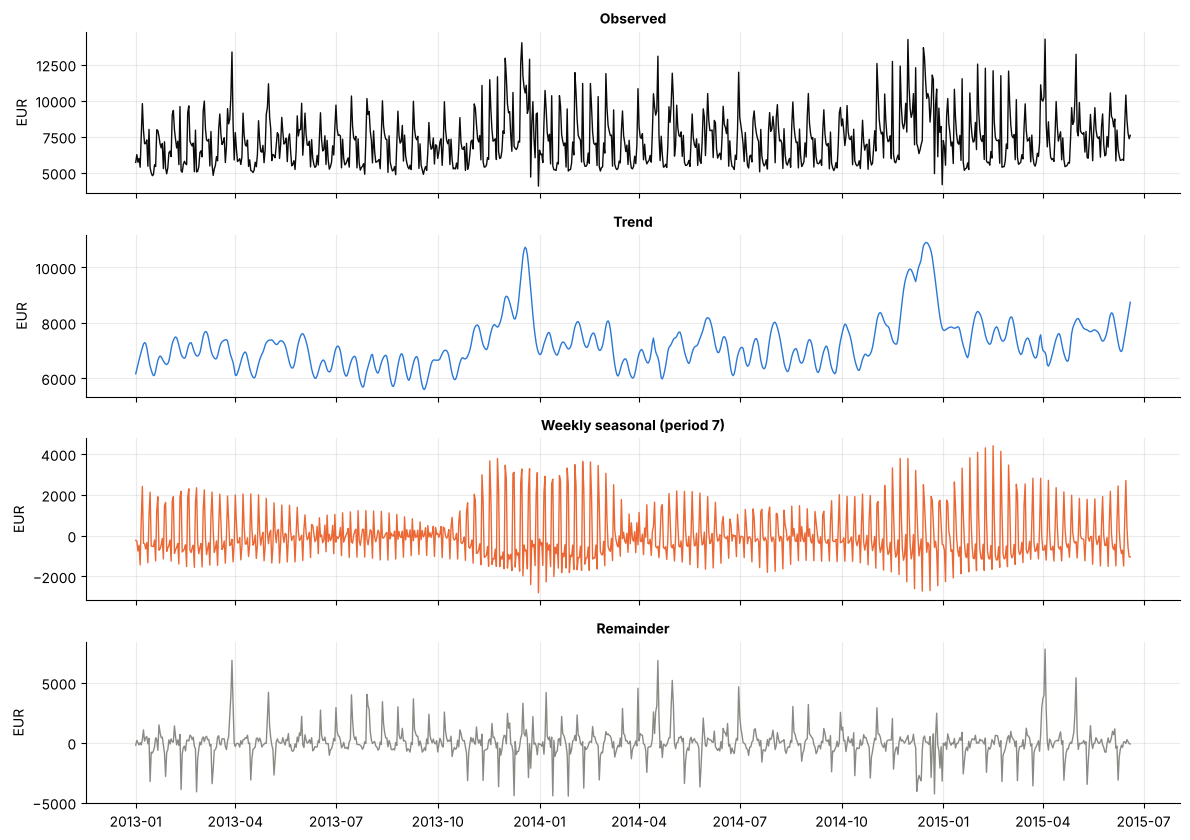

STL period (days),trend strength,seasonal strength,remainder std (EUR)
7,0.372,0.364,"1,204"
14,0.237,0.598,"1,060"


In [ ]:
stl7 = STL(y_tr, period=7, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True)
for ax, (name, comp, col) in zip(axes, [("Observed", y_tr, INK), ("Trend", stl7.trend, BLUE), ("Weekly seasonal (period 7)", stl7.seasonal, ORANGE), ("Remainder", stl7.resid, GREY)]):
    ax.plot(comp.index, comp.values, color=col, lw=1.0); ax.set_ylabel("EUR"); ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

def strengths(res):
    f_t = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())          # Wang, Smith & Hyndman (2006)
    f_s = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
    return f_t, f_s
stl14 = STL(y_tr, period=14, robust=True).fit()
rows = []
for p, r in [(7, stl7), (14, stl14)]:
    ft, fs = strengths(r); rows.append({"STL period (days)": p, "trend strength": ft, "seasonal strength": fs, "remainder std (EUR)": r.resid.std()})
st_tbl = pd.DataFrame(rows); display(st_tbl.style.format({"trend strength": "{:.3f}", "seasonal strength": "{:.3f}", "remainder std (EUR)": "{:,.0f}"}).hide(axis="index"))

In [ ]:
fs7, fs14 = st_tbl["seasonal strength"]; sd7, sd14 = st_tbl["remainder std (EUR)"]
display(Markdown(
f"**Reading the table.** Strength runs from 0 (none) to 1 (everything explained by that component). Weekly seasonality (period 7) has strength **{fs7:.2f}**; "
f"using a period of 14 days raises it to **{fs14:.2f}** and lowers the remainder spread from {sd7:,.0f} to {sd14:,.0f} EUR. "
f"{'The two-week cycle therefore adds explanatory power beyond the weekly pattern.' if fs14 > fs7 else 'A two-week period does not add explanatory power beyond the weekly pattern in this decomposition.'}" + " Note that the STL trend also contains the December peaks (see the plot), because only a weekly period was modelled; ‘trend strength’ therefore partly measures yearly seasonality."))

**Reading the table.** Strength runs from 0 (none) to 1 (everything explained by that component). Weekly seasonality (period 7) has strength **0.36**; using a period of 14 days raises it to **0.60** and lowers the remainder spread from 1,204 to 1,060 EUR. The two-week cycle therefore adds explanatory power beyond the weekly pattern. Note that the STL trend also contains the December peaks (see the plot), because only a weekly period was modelled; ‘trend strength’ therefore partly measures yearly seasonality.

### 4.1 Where does a two-week rhythm come from? The promotion calendar
`Promo` is a *planned, known-in-advance* flag. If the chain alternates promotion weeks, the share of trading stores on promotion should switch on and off every other week, and sales should follow.

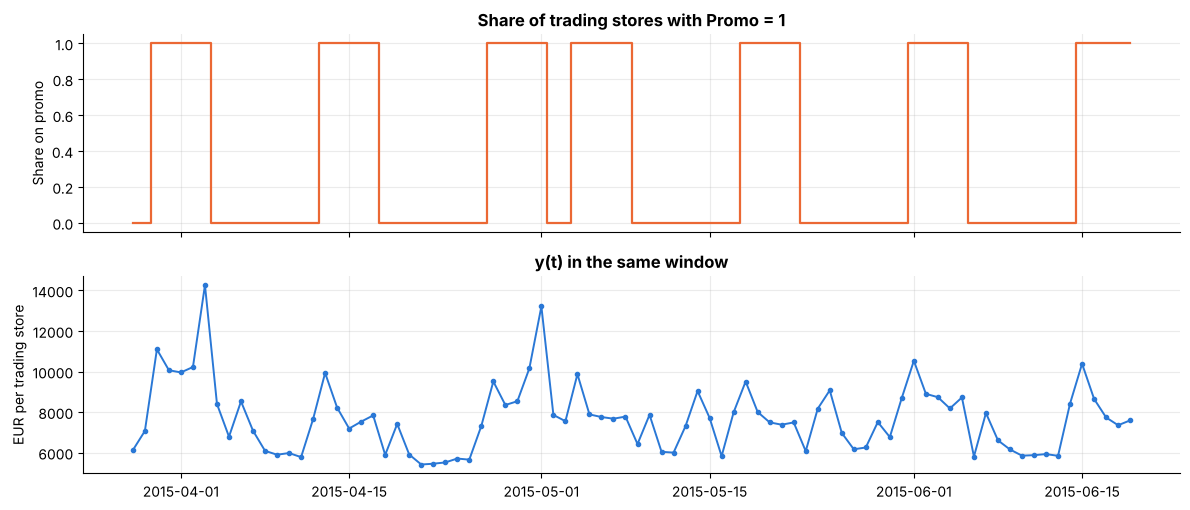

**Finding.** On Mon–Fri training days the chain-wide promo share is above 50 % on **54%** of the days; sales per trading store are **+37%** higher on those days (correlation between promo share and y(t): **0.66**). So a large part of the two-week rhythm is the promotion calendar, which is **known in advance** and could be supplied to a model as an extra input.

In [ ]:
promo_share = op.groupby("Date").Promo.mean().reindex(daily.index)
win = slice(last_day - pd.Timedelta(days=125), last_day - pd.Timedelta(days=42))      # a window inside the training part
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
axes[0].step(promo_share[win].index, promo_share[win].values, where="mid", color=ORANGE, lw=1.6); axes[0].set_ylabel("Share on promo"); axes[0].set_title("Share of trading stores with Promo = 1")
axes[1].plot(y[win].index, y[win].values, color=BLUE, lw=1.4, marker="o", ms=3); axes[1].set_ylabel("EUR per trading store"); axes[1].set_title("y(t) in the same window")
plt.tight_layout(); plt.show()

wd = y_tr.index.dayofweek < 5                                                            # Mon-Fri only, to remove the weekend effect
hi = promo_share[y_tr.index][wd] > .5
corr_p = np.corrcoef(promo_share[y_tr.index][wd], y_tr[wd])[0, 1]
uplift = y_tr[wd][hi].mean() / y_tr[wd][~hi].mean() - 1
display(Markdown(f"**Finding.** On Mon–Fri training days the chain-wide promo share is above 50 % on **{hi.mean():.0%}** of the days; sales per trading store are **{uplift:+.0%}** higher on those days "
                 f"(correlation between promo share and y(t): **{corr_p:.2f}**). So a large part of the two-week rhythm is the promotion calendar, which is **known in advance** and could be supplied to a model as an extra input."))

### 4.2 Yearly pattern
Only 2013 and 2014 are complete calendar years; each month is expressed relative to the mean of its own year so that the two years can be compared on one scale.

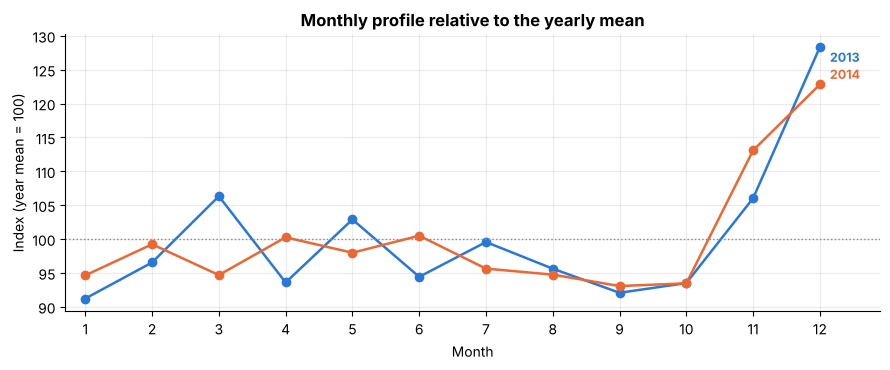

**Finding.** Both years peak in month **12** (index 126) and are lowest in month **9** (index 93); the two yearly shapes have a correlation of **0.83**. This is the yearly (Christmas) seasonality that a model trained on 2.6 years sees only twice and that the 42-day hold-out (June–July) does **not** test.

In [ ]:
full = ym[[2013, 2014]]; idx = full / full.mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.8))
for yr, col in zip([2013, 2014], [BLUE, ORANGE]):
    ax.plot(idx.index, idx[yr], marker="o", color=col, lw=1.8); ax.text(12.15, idx[yr].iloc[-1] + (-1.5 if yr == 2013 else 1.5), str(yr), color=col, va="center", fontsize=9, fontweight="bold")
ax.axhline(100, color=GREY, lw=1, ls=":"); ax.set_xticks(range(1, 13)); ax.set_xlim(.7, 12.9); ax.set_xlabel("Month"); ax.set_ylabel("Index (year mean = 100)")
ax.set_title("Monthly profile relative to the yearly mean"); plt.tight_layout(); plt.show()
peak = idx.mean(axis=1).idxmax(); low = idx.mean(axis=1).idxmin(); corr_years = idx[2013].corr(idx[2014])
display(Markdown(f"**Finding.** Both years peak in month **{peak}** (index {idx.mean(axis=1).max():.0f}) and are lowest in month **{low}** (index {idx.mean(axis=1).min():.0f}); the two yearly shapes have a correlation of **{corr_years:.2f}**. "
                 "This is the yearly (Christmas) seasonality that a model trained on 2.6 years sees only twice and that the 42-day hold-out (June–July) does **not** test."))

## 5. Weekday and weekend patterns

,avg stores trading,avg sales per trading store,avg total sales
Mon,"1,022","8,226","8,400,824"
Tue,"1,064","7,085","7,530,470"
Wed,"1,048","6,770","7,049,873"
Thu,992,"6,931","6,711,021"
Fri,"1,023","7,313","7,237,717"
Sat,"1,073","5,890","6,317,202"
Sun,27,"8,592","218,034"


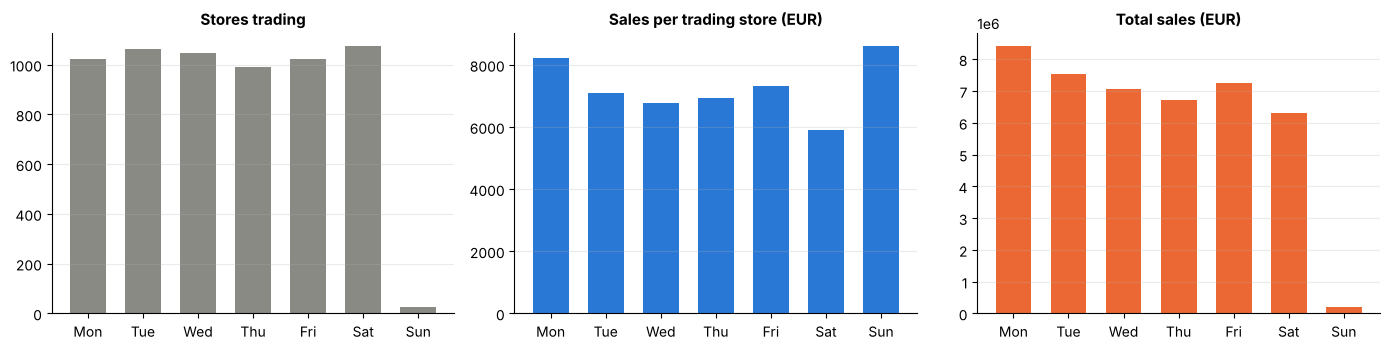

**Findings.** Highest sales per trading store: **Sun** (8,592 EUR); lowest: **Sat** (5,890 EUR). On Sundays only **27** stores trade (vs ≈ 1,022 on Mondays), so the Sunday value of y(t) describes a small, special group of stores — its high average is likely largely a composition effect (section 7 shows which store types trade on Sundays). Saturday and Sunday together carry **15.0%** of total sales.

In [ ]:
dn = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow = pd.DataFrame({"avg stores trading": daily.n_trading[daily.index < cut].groupby(daily.index[daily.index < cut].dayofweek).mean(),
                    "avg sales per trading store": y_tr.groupby(y_tr.index.dayofweek).mean(),
                    "avg total sales": tot_tr.groupby(tot_tr.index.dayofweek).mean()})
dow.index = dn; display(dow.style.format({"avg stores trading": "{:,.0f}", "avg sales per trading store": "{:,.0f}", "avg total sales": "{:,.0f}"}))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, ttl, c in zip(axes, dow.columns, ["Stores trading", "Sales per trading store (EUR)", "Total sales (EUR)"], [GREY, BLUE, ORANGE]):
    ax.bar(dow.index, dow[col], color=c, width=.65); ax.set_title(ttl, fontsize=11); ax.grid(axis="x", alpha=0)
plt.tight_layout(); plt.show()
wkend_share = tot_tr[tot_tr.index.dayofweek >= 5].sum() / tot_tr.sum()
best_day = dow["avg sales per trading store"].idxmax(); worst_day = dow["avg sales per trading store"].idxmin()
display(Markdown(f"**Findings.** Highest sales per trading store: **{best_day}** ({dow.loc[best_day, 'avg sales per trading store']:,.0f} EUR); lowest: **{worst_day}** ({dow.loc[worst_day, 'avg sales per trading store']:,.0f} EUR). "
                 f"On Sundays only **{dow.loc['Sun', 'avg stores trading']:,.0f}** stores trade (vs ≈ {dow.loc['Mon', 'avg stores trading']:,.0f} on Mondays), so the Sunday value of y(t) describes a small, special group of stores — its high average is likely largely a composition effect (section 7 shows which store types trade on Sundays). "
                 f"Saturday and Sunday together carry **{wkend_share:.1%}** of total sales."))

## 6. Holiday effects
`StateHoliday` codes: `a` public holiday, `b` Easter holiday, `c` Christmas. Most stores are closed on these days, so we look at **two** quantities around each holiday date:
* **Total sales index** — includes the effect of stores being closed.
* **Sales per trading store index** — what the stores that *are* open sell.

**Method (event study).** For every holiday date *h* and offset *k* (days before/after) we divide the value on day *h+k* by the average of the *same weekday* 2 and 4 weeks before and after (*h+k ± 14, ± 28 days*; ±14 keeps the same promotion phase of the two-week cycle). Days within 3 days of any holiday are excluded from that baseline. An index of 1.00 means “as on a normal day”.

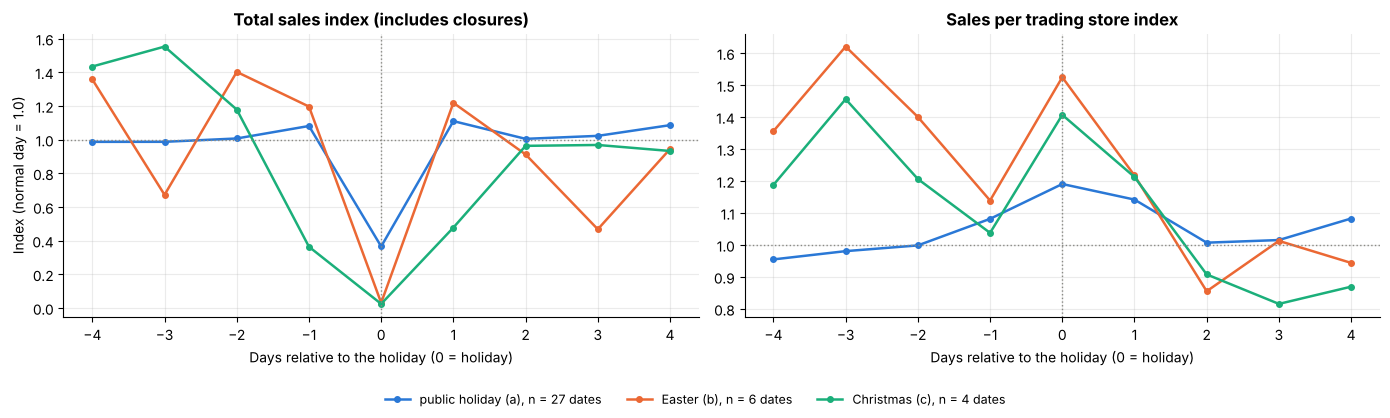

In [ ]:
hol_by_type = {t: pd.DatetimeIndex(sorted(g.Date.unique())) for t, g in train[train.StateHoliday != "0"].groupby("StateHoliday")}
all_hol = sorted(set(d for idx_ in hol_by_type.values() for d in idx_))
near = {h + pd.Timedelta(days=k) for h in all_hol for k in range(-3, 4)}
TYPE_NAME = {"a": "public holiday (a)", "b": "Easter (b)", "c": "Christmas (c)"}

def event_index(series, dates, offsets, step=14, js=(-2, -1, 1, 2)):
    out = {}
    for k in offsets:
        vals = []
        for h in dates:
            t = pd.Timestamp(h) + pd.Timedelta(days=k)
            if t not in series.index: continue
            cand = [t + pd.Timedelta(days=step * j) for j in js]
            cand = [c for c in cand if c in series.index and c not in near]
            if cand: vals.append(series[t] / series[cand].mean())
        out[k] = (np.mean(vals) if vals else np.nan, len(vals))
    return pd.DataFrame(out, index=["index", "n_events"]).T

offsets = list(range(-4, 5))
res = {t: {"total": event_index(tot_tr, [d for d in hol_by_type[t] if d < cut], offsets),
           "per_store": event_index(y_tr, [d for d in hol_by_type[t] if d < cut], offsets)} for t in hol_by_type}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharex=True)
for t, col in zip(hol_by_type, [BLUE, ORANGE, AQUA]):
    for ax, key in zip(axes, ["total", "per_store"]):
        ax.plot(offsets, res[t][key]["index"], marker="o", ms=4, color=col, lw=1.8, label=f"{TYPE_NAME[t]}, n = {int(res[t][key].n_events.max())} dates")
for ax, ttl in zip(axes, ["Total sales index (includes closures)", "Sales per trading store index"]):
    ax.axhline(1, color=GREY, ls=":", lw=1); ax.axvline(0, color=GREY, ls=":", lw=1); ax.set_xlabel("Days relative to the holiday (0 = holiday)"); ax.set_title(ttl)
axes[0].set_ylabel("Index (normal day = 1.0)"); h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, .08, 1, 1]); plt.show()

In [ ]:
tot0 = {t: res[t]["total"].loc[0, "index"] for t in res}; ps0 = {t: res[t]["per_store"].loc[0, "index"] for t in res}
pre = {t: res[t]["per_store"].loc[[-2, -1], "index"].mean() for t in res}; post = {t: res[t]["per_store"].loc[[1, 2], "index"].mean() for t in res}
lines = [f"* **{TYPE_NAME[t]}** — on the day: total sales at **{tot0[t]:.2f}** of normal, per trading store **{ps0[t]:.2f}**; "
         f"1–2 days before: **{pre[t]:.2f}**, 1–2 days after: **{post[t]:.2f}** (per trading store)." for t in res]
display(Markdown("**Findings (training part).**\n" + "\n".join(lines) +
                 "\n\nSmall event counts (Easter and Christmas have only a few dates in the data) mean these averages are indicative, not precise. "
                 "A pure univariate series model cannot know a holiday is coming; a holiday calendar is a **known-in-advance input** and should be given to a model when it is allowed."))

**Findings (training part).**
* **public holiday (a)** — on the day: total sales at **0.37** of normal, per trading store **1.19**; 1–2 days before: **1.04**, 1–2 days after: **1.07** (per trading store).
* **Easter (b)** — on the day: total sales at **0.03** of normal, per trading store **1.52**; 1–2 days before: **1.27**, 1–2 days after: **1.04** (per trading store).
* **Christmas (c)** — on the day: total sales at **0.02** of normal, per trading store **1.41**; 1–2 days before: **1.12**, 1–2 days after: **1.06** (per trading store).

Small event counts (Easter and Christmas have only a few dates in the data) mean these averages are indicative, not precise. A pure univariate series model cannot know a holiday is coming; a holiday calendar is a **known-in-advance input** and should be given to a model when it is allowed.

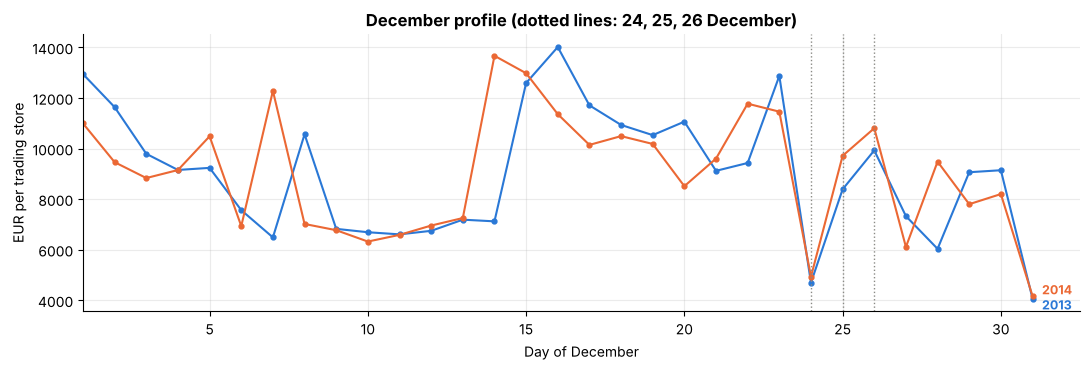

In [ ]:
# Christmas month: day-by-day profile of December (training part)
fig, ax = plt.subplots(figsize=(11, 3.8))
for yr, col in zip([2013, 2014], [BLUE, ORANGE]):
    d = y_tr[(y_tr.index.year == yr) & (y_tr.index.month == 12)]
    ax.plot(d.index.day, d.values, marker="o", ms=3.5, lw=1.5, color=col); ax.text(d.index.day[-1] + .3, d.values[-1] + (-250 if yr == 2013 else 250), str(yr), color=col, va="center", fontsize=9, fontweight="bold")
for dday in (24, 25, 26): ax.axvline(dday, color=GREY, ls=":", lw=1)
ax.set_xlabel("Day of December"); ax.set_ylabel("EUR per trading store"); ax.set_title("December profile (dotted lines: 24, 25, 26 December)"); ax.set_xlim(1, 32.5)
plt.tight_layout(); plt.show()

## 7. Store-type temporal patterns
Stores come in four types (`a`, `b`, `c`, `d`). Do they follow the same time pattern? To compare the *shape* (not the size), each type is indexed to its own average (= 100). Type `b` has very few stores and is therefore noisy.

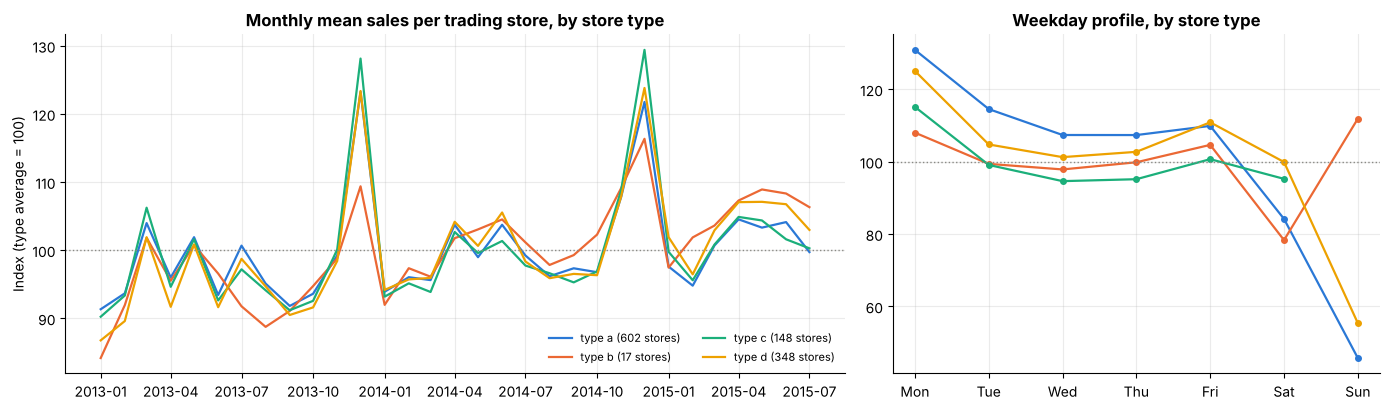

,stores,stores that ever trade on a Sunday,avg sales per trading store (EUR),share trading on Sundays
a,602,13,"6,926",2%
b,17,17,"10,233",100%
c,148,0,"6,933",0%
d,348,3,"6,822",1%


**Findings.** The monthly shapes of the store types are strongly correlated (lowest pairwise correlation **0.79**), so the *timing* of seasonality is shared and the types differ mostly in level. Type with the highest average sales per trading store: **b**. Of the 33 stores that ever trade on a Sunday, 17 belong to type **b** — the type with the highest sales per trading store — so Sunday values of y(t) reflect a few stores, not a general weekend pattern.

In [ ]:
stype = op.Store.map(store.set_index("Store").StoreType)
n_stores = store.StoreType.value_counts().sort_index()
monthly = op.groupby([op.Date.dt.to_period("M"), stype]).Sales.mean().unstack()
monthly_idx = monthly / monthly.mean() * 100
dow_t = op.groupby([op.DayOfWeek, stype]).Sales.mean().unstack(); dow_idx = dow_t / dow_t.mean() * 100
cols = dict(zip(["a", "b", "c", "d"], [BLUE, ORANGE, AQUA, YELLOW]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for t in monthly_idx.columns:
    axes[0].plot(monthly_idx.index.to_timestamp(), monthly_idx[t], color=cols[t], lw=1.6, label=f"type {t} ({n_stores[t]} stores)")
    axes[1].plot(dn, dow_idx[t].values, marker="o", ms=4, color=cols[t], lw=1.6)
axes[0].axhline(100, color=GREY, ls=":", lw=1); axes[0].set_ylabel("Index (type average = 100)"); axes[0].set_title("Monthly mean sales per trading store, by store type"); axes[0].legend(frameon=False, ncol=2, fontsize=8)
axes[1].axhline(100, color=GREY, ls=":", lw=1); axes[1].set_title("Weekday profile, by store type")
plt.tight_layout(); plt.show()

sun_open = op[op.DayOfWeek == 7].groupby(stype[op.DayOfWeek == 7]).Store.nunique()
tbl = pd.DataFrame({"stores": n_stores, "stores that ever trade on a Sunday": sun_open.reindex(n_stores.index).fillna(0).astype(int),
                    "avg sales per trading store (EUR)": op.groupby(stype).Sales.mean()})
tbl["share trading on Sundays"] = tbl.iloc[:, 1] / tbl.stores
display(tbl.style.format({"avg sales per trading store (EUR)": "{:,.0f}", "share trading on Sundays": "{:.0%}"}))
c_ab = monthly_idx.corr()
display(Markdown(f"**Findings.** The monthly shapes of the store types are strongly correlated (lowest pairwise correlation **{c_ab.values[np.triu_indices(4, 1)].min():.2f}**), so the *timing* of seasonality is shared and the types differ mostly in level. "
                 f"Type with the highest average sales per trading store: **{tbl['avg sales per trading store (EUR)'].idxmax()}**. Of the {int(tbl.iloc[:, 1].sum())} stores that ever trade on a Sunday, {int(tbl.iloc[:, 1].max())} belong to type **{tbl.iloc[:, 1].idxmax()}**{' — the type with the highest sales per trading store —' if tbl.iloc[:, 1].idxmax() == tbl['avg sales per trading store (EUR)'].idxmax() else ''} so Sunday values of y(t) reflect a few stores, not a general weekend pattern."))

## 8. Stationarity (ADF and KPSS) and the differencing decision

A series is **stationary** if its mean, variance and autocorrelation do not drift over time. Many forecasting methods work best on stationary data; differencing (`x(t) − x(t−1)`, or a seasonal `x(t) − x(t−7)`) is the usual cure for a trend.

Two tests with **opposite** null hypotheses are used together:
* **ADF** — H0: the series has a unit root (is *non*-stationary). Small p-value (< 0.05) → reject H0 → evidence of stationarity.
* **KPSS** — H0: the series *is* stationary. Small p-value (< 0.05) → reject H0 → evidence of non-stationarity.

| ADF | KPSS | Reading |
|---|---|---|
| rejects | does not reject | stationary |
| does not reject | rejects | non-stationary (unit root) |
| rejects | rejects | conflicting — no unit root, but a trend / seasonal pattern remains |
| does not reject | does not reject | inconclusive |

All tests use the **training part only**.

In [ ]:
def fmt_p(p):
    return "<= 0.01" if p <= 0.0101 else (">= 0.10" if p >= 0.0999 else f"{p:.3f}")

def stationarity_row(x, label, reg="c"):
    x = pd.Series(x).dropna().astype("float64")
    a_stat, a_p = adfuller(x, regression=reg, autolag="AIC")[:2]
    k_stat, k_p = kpss(x, regression=reg, nlags="auto")[:2]
    a_rej, k_rej = a_p < .05, k_p < .05
    verdict = ("stationary" if a_rej and not k_rej else "non-stationary (unit root)" if (not a_rej) and k_rej
               else "conflicting" if a_rej and k_rej else "inconclusive")
    return {"series": label, "n": len(x), "ADF stat": a_stat, "ADF p": a_p, "KPSS stat": k_stat, "KPSS p": k_p, "verdict": verdict}

rows = [stationarity_row(y_tr, "raw y(t)"),
        stationarity_row(np.log(y_tr), "log y(t)"),
        stationarity_row(y_tr.diff(), "first difference (lag 1)"),
        stationarity_row(y_tr.diff(7), "seasonal difference (lag 7)"),
        stationarity_row(y_tr.diff(14), "seasonal difference (lag 14)"),
        stationarity_row(y_tr, "raw y(t), test around a linear trend ('ct')", reg="ct")]
stt = pd.DataFrame(rows)
disp = stt.copy(); disp["ADF p"] = disp["ADF p"].map(fmt_p); disp["KPSS p"] = disp["KPSS p"].map(fmt_p)
display(disp.style.format({"ADF stat": "{:.2f}", "KPSS stat": "{:.3f}"}).hide(axis="index"))

series,n,ADF stat,ADF p,KPSS stat,KPSS p,verdict
raw y(t),900,-5.27,<= 0.01,1.098,<= 0.01,conflicting
log y(t),900,-4.77,<= 0.01,1.178,<= 0.01,conflicting
first difference (lag 1),899,-11.36,<= 0.01,0.010,>= 0.10,stationary
seasonal difference (lag 7),893,-10.06,<= 0.01,0.010,>= 0.10,stationary
seasonal difference (lag 14),886,-7.23,<= 0.01,0.015,>= 0.10,stationary
"raw y(t), test around a linear trend ('ct')",900,-5.71,<= 0.01,0.065,>= 0.10,stationary


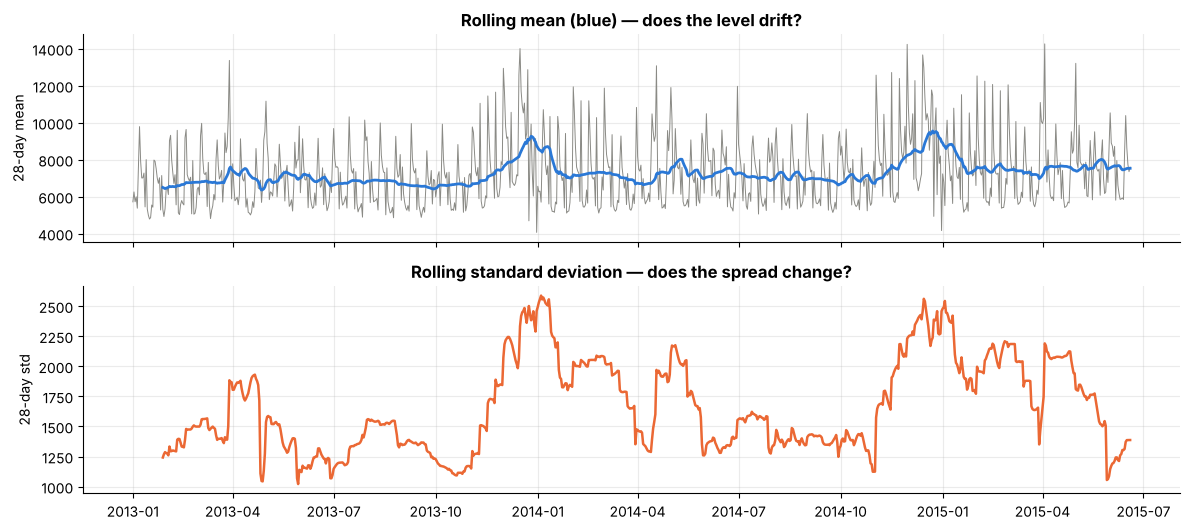

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.4), sharex=True)
axes[0].plot(y_tr.index, y_tr, color=GREY, lw=.7); axes[0].plot(y_tr.index, y_tr.rolling(28).mean(), color=BLUE, lw=2); axes[0].set_ylabel("28-day mean"); axes[0].set_title("Rolling mean (blue) — does the level drift?")
axes[1].plot(y_tr.index, y_tr.rolling(28).std(), color=ORANGE, lw=1.8); axes[1].set_ylabel("28-day std"); axes[1].set_title("Rolling standard deviation — does the spread change?")
plt.tight_layout(); plt.show()

In [ ]:
raw, d1, d7 = stt.iloc[0], stt.iloc[2], stt.iloc[3]
rule_diff = bool(raw["ADF p"] >= .05)            # decision rule, written down BEFORE looking at any model: difference only if ADF cannot reject a unit root
display(Markdown(f'''
**Results.**
* **Raw series:** ADF statistic {raw["ADF stat"]:.2f} (p {fmt_p(raw["ADF p"])}), KPSS statistic {raw["KPSS stat"]:.2f} (p {fmt_p(raw["KPSS p"])}) → **{raw["verdict"]}**.
* **First difference:** ADF p {fmt_p(d1["ADF p"])}, KPSS p {fmt_p(d1["KPSS p"])} → **{d1["verdict"]}**. **Seasonal difference (lag 7):** ADF p {fmt_p(d7["ADF p"])}, KPSS p {fmt_p(d7["KPSS p"])} → **{d7["verdict"]}**.
* Around a linear trend (`ct`): ADF p {fmt_p(stt.iloc[5]["ADF p"])}, KPSS p {fmt_p(stt.iloc[5]["KPSS p"])} → **{stt.iloc[5]["verdict"]}**.

**Differencing decision (rule fixed in advance): difference only if the ADF test cannot reject a unit root (p ≥ 0.05).**
Here the rule says: **{"difference the series" if rule_diff else "do NOT difference for the unit-root reason"}**.
{"" if rule_diff else "The ADF test rejects a unit root, but KPSS still rejects stationarity: the series has no unit root, yet it keeps a slow level change and a strong seasonal pattern (sections 3–4). That is a *trend/seasonality* problem, not a unit-root problem. Differencing can discard level information (and, for a recursive multi-week forecast, errors in differenced forecasts add up when they are summed back to levels). Therefore the recommendation for the LSTM is: feed the **undifferenced** series, scaled, with a window long enough to see the weekly and two-weekly pattern, and run differencing only as a documented sensitivity check."}
{"With a linear trend allowed for (`ct`), both tests agree that the series is stationary: the conflict above comes from the trend." if stt.iloc[5]["verdict"] == "stationary" else ""}
'''))


**Results.**
* **Raw series:** ADF statistic -5.27 (p <= 0.01), KPSS statistic 1.10 (p <= 0.01) → **conflicting**.
* **First difference:** ADF p <= 0.01, KPSS p >= 0.10 → **stationary**. **Seasonal difference (lag 7):** ADF p <= 0.01, KPSS p >= 0.10 → **stationary**.
* Around a linear trend (`ct`): ADF p <= 0.01, KPSS p >= 0.10 → **stationary**.

**Differencing decision (rule fixed in advance): difference only if the ADF test cannot reject a unit root (p ≥ 0.05).**
Here the rule says: **do NOT difference for the unit-root reason**.
The ADF test rejects a unit root, but KPSS still rejects stationarity: the series has no unit root, yet it keeps a slow level change and a strong seasonal pattern (sections 3–4). That is a *trend/seasonality* problem, not a unit-root problem. Differencing can discard level information (and, for a recursive multi-week forecast, errors in differenced forecasts add up when they are summed back to levels). Therefore the recommendation for the LSTM is: feed the **undifferenced** series, scaled, with a window long enough to see the weekly and two-weekly pattern, and run differencing only as a documented sensitivity check.
With a linear trend allowed for (`ct`), both tests agree that the series is stationary: the conflict above comes from the trend.


## 9. Autocorrelation (ACF) and partial autocorrelation (PACF)

* **ACF at lag k:** how strongly today's value is related to the value k days ago.
* **PACF at lag k:** the same, after removing the influence of the lags in between.
The shaded band marks the 95 % range expected by chance for white noise; bars outside it are statistically meaningful. Lags 1–60 are shown for the raw series and for the two differenced versions.

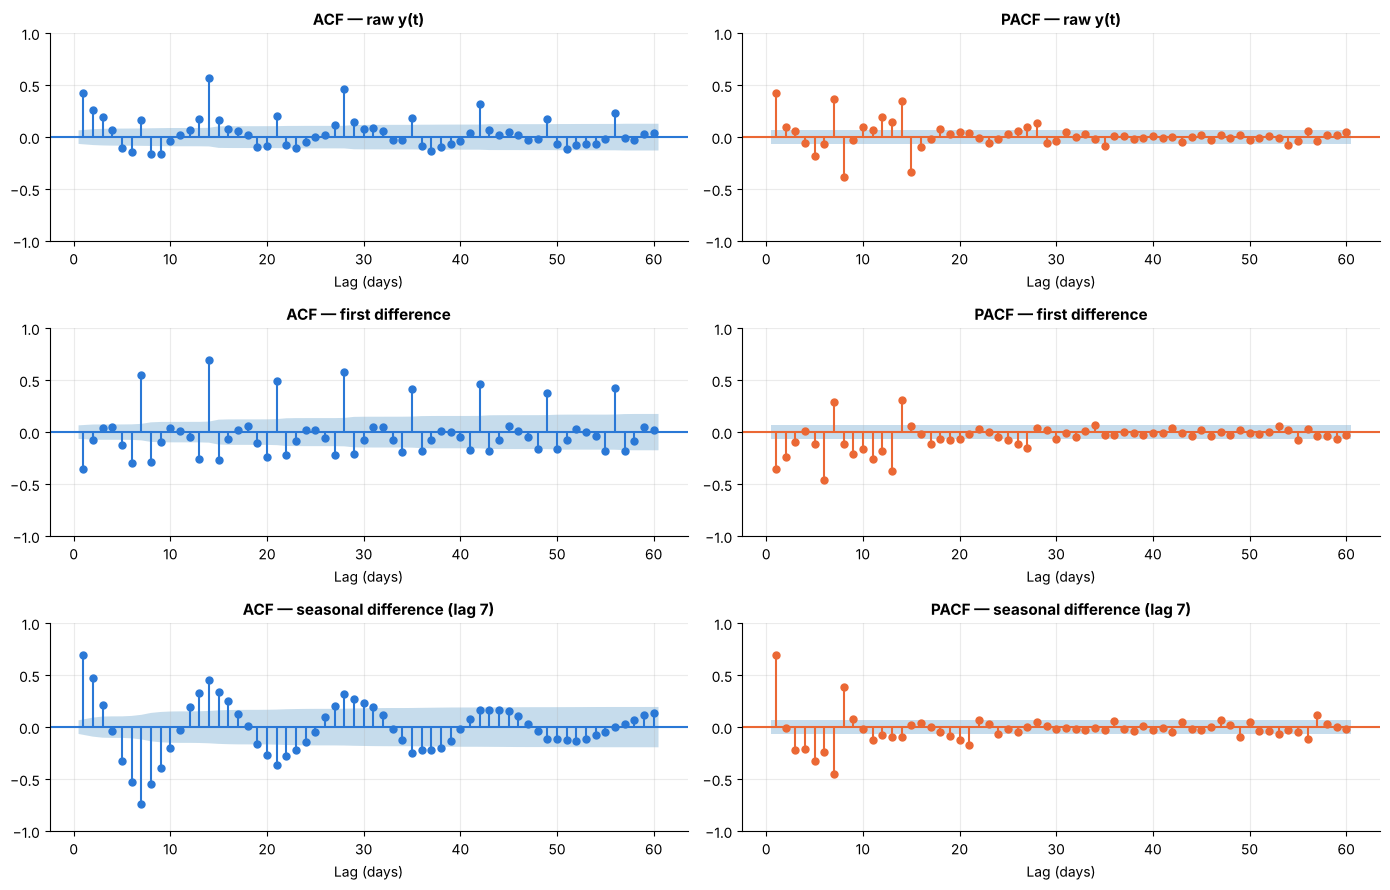

In [ ]:
LAGS = 60
fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for i, (lab, x) in enumerate([("raw y(t)", y_tr), ("first difference", y_tr.diff().dropna()), ("seasonal difference (lag 7)", y_tr.diff(7).dropna())]):
    plot_acf(x, lags=LAGS, ax=axes[i, 0], zero=False, color=BLUE, vlines_kwargs={"colors": BLUE}); axes[i, 0].set_title(f"ACF — {lab}", fontsize=11)
    plot_pacf(x, lags=LAGS, ax=axes[i, 1], zero=False, method="ywm", color=ORANGE, vlines_kwargs={"colors": ORANGE}); axes[i, 1].set_title(f"PACF — {lab}", fontsize=11)
for ax in axes.ravel(): ax.set_xlabel("Lag (days)")
plt.tight_layout(); plt.show()

In [ ]:
n = len(y_tr); band = 1.96 / np.sqrt(n)
a = acf(y_tr, nlags=LAGS); p = pacf(y_tr, nlags=LAGS, method="ywm")
a_sig = [(k, a[k]) for k in range(1, LAGS + 1) if abs(a[k]) > band]
top_acf = sorted(a_sig, key=lambda t: -abs(t[1]))[:6]
p_sig = [(k, p[k]) for k in range(1, LAGS + 1) if abs(p[k]) > band]
top_pacf = sorted(p_sig, key=lambda t: -abs(t[1]))[:6]
acf_lags_multiple = [k for k, _ in a_sig if k % 7 == 0]
n14 = sum(k % 14 == 0 for k, _ in top_acf)
d_acf = acf(y_tr.diff().dropna(), nlags=28); n_d1 = sum(abs(d_acf[k]) > band for k in (7, 14, 21, 28))
fm = lambda lst: ", ".join(f"lag {k} ({v:+.2f})" for k, v in lst)
display(Markdown(f'''
**Reading the plots (training part, n = {n}, 95 % band ±{band:.3f}).**
* **ACF, strongest lags:** {fm(top_acf)}. Significant lags that are multiples of 7: {", ".join(map(str, acf_lags_multiple)) or "none"}.
* **PACF, strongest lags:** {fm(top_pacf)}.
* {n14} of the {len(top_acf)} strongest ACF lags are multiples of 14: the two-week promotion rhythm dominates, with smaller peaks at the other multiples of 7. After first differencing, {n_d1} of the lags 7, 14, 21 and 28 are still outside the band — differencing removes the slow level change but **not** the weekly/two-week rhythm.
* **Consequence for the LSTM window:** the memory of this series reaches at least {max([k for k, _ in top_acf] or [0])} days back (strongest lags above). A window of **28 days** covers four full weeks and two full promotion cycles — see section 11.
'''))


**Reading the plots (training part, n = 900, 95 % band ±0.065).**
* **ACF, strongest lags:** lag 14 (+0.57), lag 28 (+0.46), lag 1 (+0.43), lag 42 (+0.32), lag 2 (+0.26), lag 56 (+0.23). Significant lags that are multiples of 7: 7, 14, 21, 28, 35, 42, 49, 56.
* **PACF, strongest lags:** lag 1 (+0.43), lag 8 (-0.39), lag 7 (+0.36), lag 14 (+0.35), lag 15 (-0.33), lag 12 (+0.19).
* 4 of the 6 strongest ACF lags are multiples of 14: the two-week promotion rhythm dominates, with smaller peaks at the other multiples of 7. After first differencing, 4 of the lags 7, 14, 21 and 28 are still outside the band — differencing removes the slow level change but **not** the weekly/two-week rhythm.
* **Consequence for the LSTM window:** the memory of this series reaches at least 56 days back (strongest lags above). A window of **28 days** covers four full weeks and two full promotion cycles — see section 11.


## 10. Naive benchmarks — what any forecasting model must beat

Before building an LSTM we need reference numbers from trivial forecasts. They also show how much of the pattern is already explained by *seasonality alone*. The lags (7, 14, 28) come from the ACF analysis above and were **not tuned** on the hold-out.

Two forecasting situations are scored on the chain series y(t), with the same metric as the ML notebook (RMSPE = root mean squared *percentage* error):
* **One-step ahead:** predict day *t* from actual history up to day *t−1* (this is “predict the next sale” of the PDF).
* **42 days ahead from one origin (the real business case):** no actual value after the origin is available, so the last block of days is simply repeated.

Windows: the **42 days before the hold-out** (still training part, shown for stability) and the **hold-out** (last 42 days).

In [ ]:
def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    return {"RMSPE": float(np.sqrt(np.mean(((actual - pred) / actual) ** 2))), "MAPE": float(np.mean(np.abs((actual - pred) / actual))),
            "MAE": float(np.mean(np.abs(actual - pred))), "RMSE": float(np.sqrt(np.mean((actual - pred) ** 2)))}

late_train = (y.index >= cut - pd.Timedelta(days=42)) & (y.index < cut)
windows = {"42 days before hold-out": late_train, "hold-out (last 42 days)": y.index >= cut}

# --- one-step naive forecasts (use actual history up to t-1) ---
one_step = {"same weekday last week (lag 7)": y.shift(7), "same weekday 2 weeks ago (lag 14)": y.shift(14),
            "same weekday 4 weeks ago (lag 28)": y.shift(28), "mean of lags 14 and 28": (y.shift(14) + y.shift(28)) / 2,
            "mean of lags 7, 14, 21, 28": (y.shift(7) + y.shift(14) + y.shift(21) + y.shift(28)) / 4}
rows = [{"forecast": name, "window": w, **metrics(y[m], pred[m])} for name, pred in one_step.items() for w, m in windows.items()]
tab1 = pd.DataFrame(rows)
display(Markdown("**One-step-ahead naive forecasts**"))
display(tab1.pivot(index="forecast", columns="window", values="RMSPE").loc[list(one_step)].style.format("{:.4f}"))

# --- 42-days-ahead naive forecasts from one origin: repeat the last block ---
def repeat_block(series, origin, block, horizon=42):
    hist = series[:origin].iloc[-block:].values
    return np.array([hist[i % block] for i in range(horizon)])
rec = {}
for w_name, origin in [("42 days before hold-out", cut - pd.Timedelta(days=43)), ("hold-out (last 42 days)", cut - pd.Timedelta(days=1))]:
    tgt = y[origin + pd.Timedelta(days=1): origin + pd.Timedelta(days=42)]
    for blk in (7, 14, 28):
        rec[(f"repeat the last {blk} days", w_name)] = metrics(tgt.values, repeat_block(y, origin, blk))
tab2 = pd.DataFrame(rec).T; tab2.index.names = ["forecast", "window"]
display(Markdown("**42-days-ahead naive forecasts (fixed origin)**"))
display(tab2.reset_index().pivot(index="forecast", columns="window", values="RMSPE").style.format("{:.4f}"))

**One-step-ahead naive forecasts**

window,42 days before hold-out,hold-out (last 42 days)
forecast,,
same weekday last week (lag 7),0.2561,0.3257
same weekday 2 weeks ago (lag 14),0.2162,0.0803
same weekday 4 weeks ago (lag 28),0.2570,0.1316
mean of lags 14 and 28,0.1985,0.0930
"mean of lags 7, 14, 21, 28",0.1750,0.1866


**42-days-ahead naive forecasts (fixed origin)**

window,42 days before hold-out,hold-out (last 42 days)
forecast,,
repeat the last 14 days,0.3505,0.0648
repeat the last 28 days,0.2866,0.1513
repeat the last 7 days,0.2140,0.2615


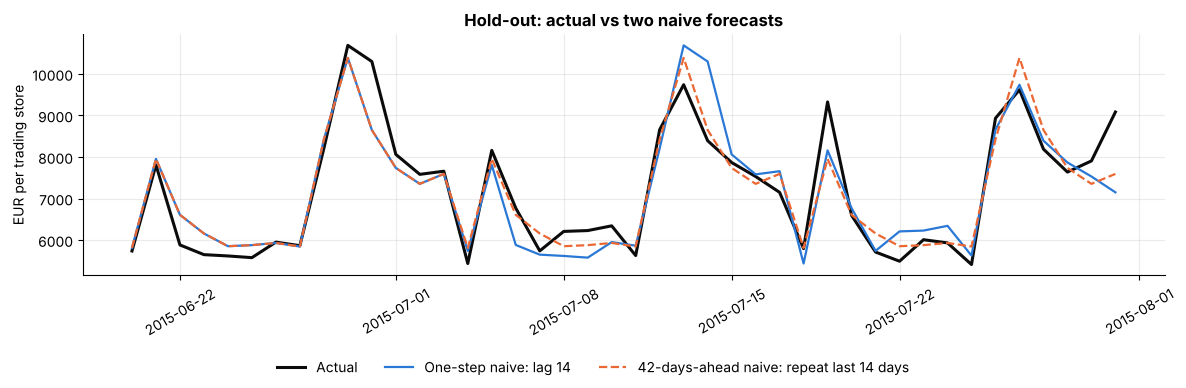

In [ ]:
org = cut - pd.Timedelta(days=1); tgt = y[y.index >= cut]
fig, ax = plt.subplots(figsize=(12, 3.9))
ax.plot(tgt.index, tgt.values, color=INK, lw=2.2, label="Actual")
ax.plot(tgt.index, one_step["same weekday 2 weeks ago (lag 14)"][tgt.index], color=BLUE, lw=1.6, label="One-step naive: lag 14")
ax.plot(tgt.index, repeat_block(y, org, 14), color=ORANGE, lw=1.6, ls="--", label="42-days-ahead naive: repeat last 14 days")
ax.set_ylabel("EUR per trading store"); ax.set_title("Hold-out: actual vs two naive forecasts"); h_, l_ = ax.get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=3, frameon=False); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(rect=[0, .08, 1, 1]); plt.show()

### 10.1 Why is the window before the hold-out so much harder?
The naive forecasts score very differently in the two windows. A likely reason: public holidays distort both the day being predicted and the reference day. This is checked directly — each window is scored on all days and on **holiday-free days only** (neither the day nor its reference day 14 days earlier lies within one day of a holiday).

In [ ]:
near1 = {h + pd.Timedelta(days=k) for h in all_hol for k in (-1, 0, 1)}
rows = []
for w, m in windows.items():
    idx_w = y.index[m]; pred = one_step["same weekday 2 weeks ago (lag 14)"][idx_w].values
    ok = np.array([(t not in near1) and (t - pd.Timedelta(days=14) not in near1) for t in idx_w])
    rows.append({"window": w, "holidays in window": ", ".join(str(d.date()) for d in all_hol if idx_w.min() <= d <= idx_w.max()) or "none",
                 "days": len(idx_w), "holiday-free days": int(ok.sum()),
                 "RMSPE lag 14, all days": metrics(y[idx_w], pred)["RMSPE"], "RMSPE lag 14, holiday-free days": metrics(y[idx_w][ok], pred[ok])["RMSPE"]})
diag = pd.DataFrame(rows)
display(diag.style.format({"RMSPE lag 14, all days": "{:.4f}", "RMSPE lag 14, holiday-free days": "{:.4f}"}).hide(axis="index"))
early_best = tab1[tab1.window == "42 days before hold-out"].RMSPE.min(); ho_hol = diag.iloc[1]["holidays in window"]
a_all, a_free = diag.iloc[0]["RMSPE lag 14, all days"], diag.iloc[0]["RMSPE lag 14, holiday-free days"]; h_free = diag.iloc[1]["RMSPE lag 14, holiday-free days"]
display(Markdown(f"In the earlier window the lag-14 forecast scores **{a_all:.4f}** on all days and **{a_free:.4f}** on its {int(diag.iloc[0]['holiday-free days'])} holiday-free days "
                 f"(hold-out: {h_free:.4f}). {'Holidays explain most of the difference.' if a_free < (a_all + h_free) / 2 else 'Holidays explain only part of the difference — the benchmark is unstable between windows.'} "
                 f"The hold-out window contains {'no holiday' if ho_hol == 'none' else 'these holidays: ' + ho_hol}."))

window,holidays in window,days,holiday-free days,"RMSPE lag 14, all days","RMSPE lag 14, holiday-free days"
42 days before hold-out,"2015-05-14, 2015-05-25, 2015-06-04",42,23,0.2162,0.1703
hold-out (last 42 days),none,42,42,0.0803,0.0803


In the earlier window the lag-14 forecast scores **0.2162** on all days and **0.1703** on its 23 holiday-free days (hold-out: 0.0803). Holidays explain only part of the difference — the benchmark is unstable between windows. The hold-out window contains no holiday.

In [ ]:
h = "hold-out (last 42 days)"
best1 = tab1[tab1.window == h].sort_values("RMSPE").iloc[0]; worst1 = tab1[tab1.window == h].sort_values("RMSPE").iloc[-1]
tab2r = tab2.reset_index(); best2 = tab2r[tab2r.window == h].sort_values("RMSPE").iloc[0]
l7 = tab1[(tab1.forecast.str.contains("lag 7)", regex=False)) & (tab1.window == h)].RMSPE.iloc[0]; l14 = tab1[(tab1.forecast.str.contains("lag 14)", regex=False)) & (tab1.window == h)].RMSPE.iloc[0]
display(Markdown(
f"**Findings (hold-out).** Best one-step naive: **{best1.forecast}** with RMSPE **{best1.RMSPE:.4f}** (worst: {worst1.forecast}, {worst1.RMSPE:.4f}). "
f"“Same weekday last week” scores {l7:.4f} but “same weekday two weeks ago” scores {l14:.4f}: "
f"{'lag 14 is better than lag 7, because last week is in the opposite promotion phase.' if l14 < l7 else 'lag 7 is not worse than lag 14 here.'} "
f"Best 42-days-ahead naive: **{best2.forecast}** with RMSPE **{best2.RMSPE:.4f}**. "
f"Caution: in the 42 days before the hold-out the best one-step naive scores {early_best:.4f} (hold-out: {best1.RMSPE:.4f}); the hold-out window contains {'no holiday' if ho_hol == 'none' else 'holidays'}, which makes it an easy window (section 10.1). "
    "These are the numbers a model has to beat; they also give the **scale of the task**: errors are measured on a chain-wide average, which is much smoother than a single store's sales, so these RMSPE values are not comparable with store-level RMSPE in the ML notebook."))

**Findings (hold-out).** Best one-step naive: **same weekday 2 weeks ago (lag 14)** with RMSPE **0.0803** (worst: same weekday last week (lag 7), 0.3257). “Same weekday last week” scores 0.3257 but “same weekday two weeks ago” scores 0.0803: lag 14 is better than lag 7, because last week is in the opposite promotion phase. Best 42-days-ahead naive: **repeat the last 14 days** with RMSPE **0.0648**. Caution: in the 42 days before the hold-out the best one-step naive scores 0.1750 (hold-out: 0.0803); the hold-out window contains no holiday, which makes it an easy window (section 10.1). These are the numbers a model has to beat; they also give the **scale of the task**: errors are measured on a chain-wide average, which is much smoother than a single store's sales, so these RMSPE values are not comparable with store-level RMSPE in the ML notebook.

## 11. Insights and decisions handed to the LSTM notebook

In [ ]:
sig_multiples = ", ".join(map(str, acf_lags_multiple))
handoff = pd.DataFrame([
    ("Series", f"y(t) = average sales per trading store and day, {len(y)} days ({y.index.min().date()} → {last_day.date()}), regular daily index, no missing days"),
    ("Split", f"training part {len(y_tr)} days; hold-out = last 42 days; all decisions below use the training part only"),
    ("Stationarity", f"raw series: {raw['verdict']} (ADF p {fmt_p(raw['ADF p'])}, KPSS p {fmt_p(raw['KPSS p'])})"),
    ("Differencing", "difference the series" if rule_diff else "no differencing by the pre-set rule; run lag-1 differencing only as a sensitivity check"),
    ("Strongest autocorrelation", fm(top_acf[:4])),
    ("Window length", "28 days as the default (covers 4 weeks and two 14-day promotion cycles; strongest ACF lags: " + ", ".join(str(k) for k, _ in top_acf) + "); try 42 days as a sensitivity check"),
    ("Scaling", "MinMaxScaler to (-1, 1), fitted on the training windows only (never on validation/hold-out values)"),
    ("Known-in-advance inputs", "promotion calendar and holidays could be added as extra channels; the pure univariate series cannot know them"),
    ("Benchmark to beat (hold-out)", f"one-step: {best1.forecast} RMSPE {best1.RMSPE:.4f}; 42 days ahead: {best2.forecast} RMSPE {best2.RMSPE:.4f} (hold-out is an easy, holiday-free window; the 42 days before it score {early_best:.4f} for the best one-step naive)"),
], columns=["Topic", "Decision / finding"])
display(handoff.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Topic,Decision / finding
Series,"y(t) = average sales per trading store and day, 942 days (2013-01-01 → 2015-07-31), regular daily index, no missing days"
Split,training part 900 days; hold-out = last 42 days; all decisions below use the training part only
Stationarity,"raw series: conflicting (ADF p <= 0.01, KPSS p <= 0.01)"
Differencing,no differencing by the pre-set rule; run lag-1 differencing only as a sensitivity check
Strongest autocorrelation,"lag 14 (+0.57), lag 28 (+0.46), lag 1 (+0.43), lag 42 (+0.32)"
Window length,"28 days as the default (covers 4 weeks and two 14-day promotion cycles; strongest ACF lags: 14, 28, 1, 42, 2, 56); try 42 days as a sensitivity check"
Scaling,"MinMaxScaler to (-1, 1), fitted on the training windows only (never on validation/hold-out values)"
Known-in-advance inputs,promotion calendar and holidays could be added as extra channels; the pure univariate series cannot know them
Benchmark to beat (hold-out),"one-step: same weekday 2 weeks ago (lag 14) RMSPE 0.0803; 42 days ahead: repeat the last 14 days RMSPE 0.0648 (hold-out is an easy, holiday-free window; the 42 days before it score 0.1750 for the best one-step naive)"


**Limitations of this analysis**
1. **One aggregated series.** y(t) hides differences between stores; store-level behaviour was only touched through store types.
2. **Store mix.** The average per trading store changes with the number and type of stores trading (especially on Sundays and holidays). The fixed-panel check in section 2 measures how much this matters, but it does not remove the effect from y(t).
3. **Short history.** 2.6 years allow only two full Christmas seasons; yearly seasonality can be seen but not estimated reliably, and the 42-day hold-out (June–July) does not test it.
4. **Few holiday events.** Easter and Christmas have only a handful of dates, so the event-study averages are indicative.
5. **Tests on a seasonal, trending series.** ADF and KPSS are sensitive to their settings; that is why both are shown, together with differenced versions and a trend variant.